# 02 - Temporal EDA

**Question:** how did PM2.5 and PM10 change in Seoul between 2017 and 2019, and how do they vary by season, weekday and hour?

Concentrations are right-skewed, so medians and percentiles are reported next to means. Reference values: Korean daily grades (PM2.5 Bad above 35 ug/m3, PM10 Bad above 80 ug/m3), Korean annual standards (PM2.5 15, PM10 50 ug/m3) and the WHO 2021 guidelines (24-hour: PM2.5 15, PM10 45; annual: PM2.5 5, PM10 15 ug/m3).

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air.grades import GRADE_LABELS
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly.parquet")
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
GRADE_COLORS = {"Good": "#1f77b4", "Moderate": "#2ca02c", "Bad": "#f2a900", "Very bad": "#d62728"}
# City-wide daily value: mean of the valid station daily means
city = daily.groupby("date")[list(config.POLLUTANTS)].mean()
print(daily.shape, city.shape)

(27375, 11) (1095, 6)


## 2. Daily series and long-term level

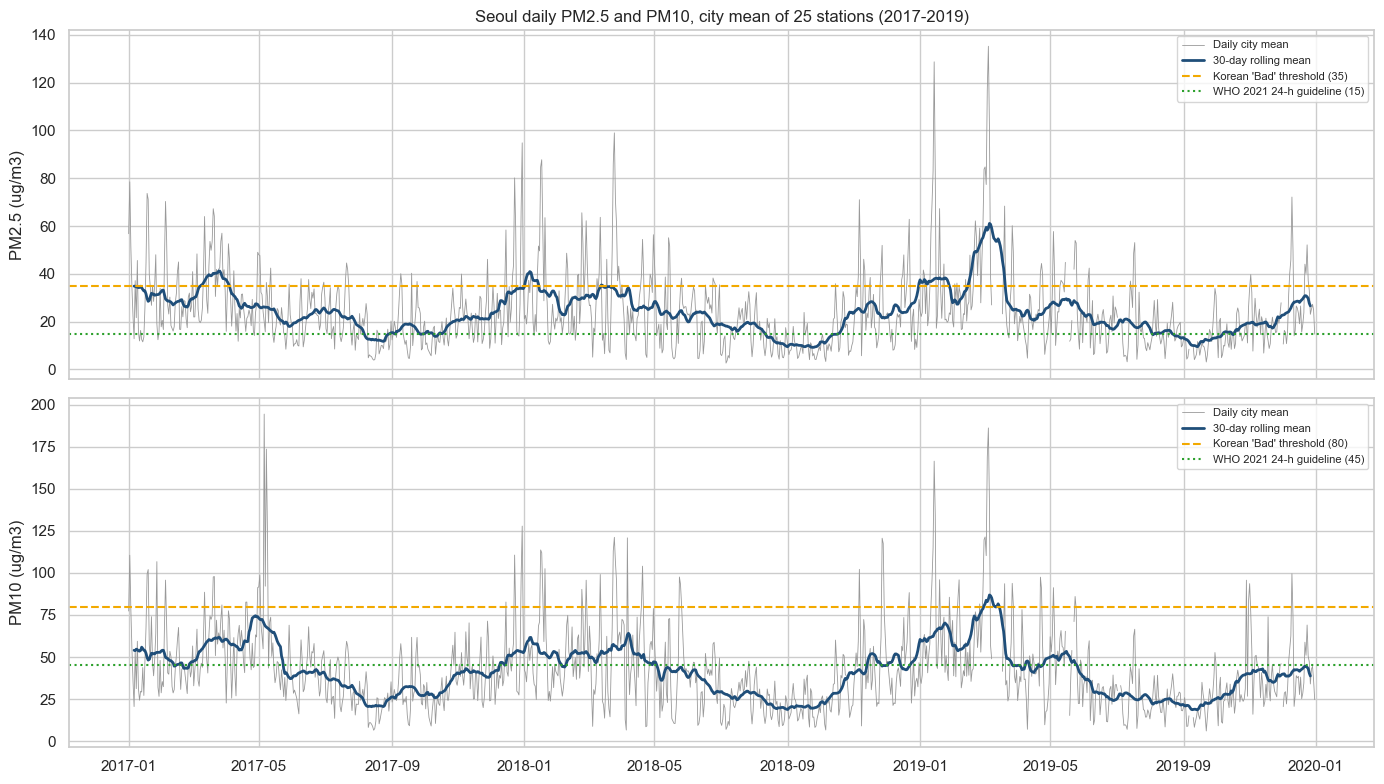

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, (col, bad, who) in zip(axes, [("pm25", 35, 15), ("pm10", 80, 45)]):
    ax.plot(city.index, city[col], lw=0.6, color="0.6", label="Daily city mean")
    ax.plot(city.index, city[col].rolling(30, center=True, min_periods=20).mean(),
            lw=2, color="#1f4e79", label="30-day rolling mean")
    ax.axhline(bad, color="#f2a900", ls="--", label=f"Korean 'Bad' threshold ({bad})")
    ax.axhline(who, color="#2ca02c", ls=":", label=f"WHO 2021 24-h guideline ({who})")
    ax.set_ylabel(f"{col.upper().replace('PM25', 'PM2.5')} (ug/m3)")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_title("Seoul daily PM2.5 and PM10, city mean of 25 stations (2017-2019)")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_daily_series.png", dpi=120)
plt.show()

In [4]:
d = daily.assign(year=daily["date"].dt.year)
annual = d.groupby("year").agg(
    pm25_mean=("pm25", "mean"), pm25_median=("pm25", "median"),
    pm25_p90=("pm25", lambda s: s.quantile(0.9)),
    pm10_mean=("pm10", "mean"), pm10_median=("pm10", "median"),
)
valid_grade = d.dropna(subset=["pm25"])
annual["pm25_bad_or_worse_days_%"] = (valid_grade.groupby("year")["pm25_grade"]
                                      .apply(lambda g: g.isin(["Bad", "Very bad"]).mean() * 100))
annual["pm25_above_who_24h_%"] = valid_grade.groupby("year")["pm25"].apply(lambda s: (s.round() > 15).mean() * 100)
annual.round(1)

,pm25_mean,pm25_median,pm25_p90,pm10_mean,pm10_median,pm25_bad_or_worse_days_%,pm25_above_who_24h_%
year,,,,,,,
2017,24.6,21.6,42.9,43.7,39.5,17.8,71.2
2018,22.8,19.7,42.5,39.6,35.5,16.8,63.6
2019,24.9,20.3,46.0,42.0,35.6,17.5,67.8


**Interpretation.** Over 2017-2019 there is no clear downward trend: the mean of the station-day PM2.5 values is 24.6, 22.8 and 24.9 ug/m3, all above the Korean annual standard of 15 and far above the WHO annual guideline of 5. Between 16.8% and 17.8% of station-days are graded Bad or Very bad each year, and 63.6% to 71.2% exceed the WHO 24-hour guideline. Three years are too short to separate a trend from year-to-year weather variation.

## 3. Seasonality

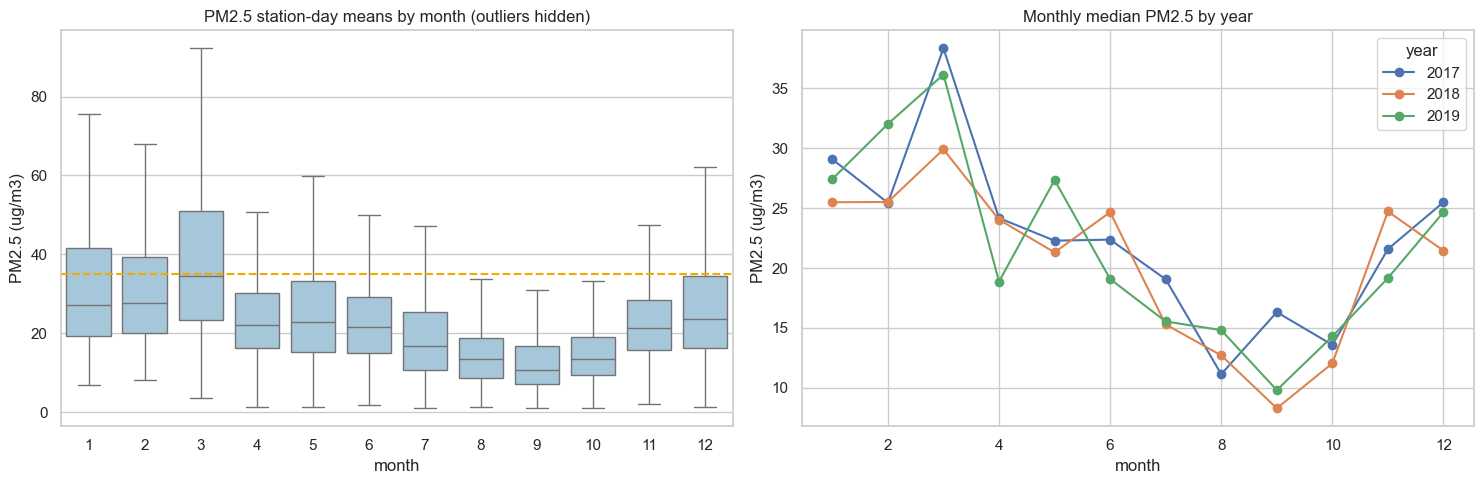

month          1     2     3     4     5     6     7     8     9     10    11    12
pm25_median  27.1  27.7  34.4  22.1  23.0  21.7  16.8  13.4  10.7  13.5  21.2  23.7


In [5]:
d["month"] = d["date"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=d, x="month", y="pm25", color="#9ecae1", showfliers=False, ax=axes[0])
axes[0].axhline(35, color="#f2a900", ls="--")
axes[0].set_title("PM2.5 station-day means by month (outliers hidden)")
axes[0].set_ylabel("PM2.5 (ug/m3)")
monthly_median = d.groupby(["year", "month"])["pm25"].median().unstack(0)
monthly_median.plot(ax=axes[1], marker="o")
axes[1].set_title("Monthly median PM2.5 by year")
axes[1].set_ylabel("PM2.5 (ug/m3)")
fig.tight_layout()
fig.savefig(config.FIGURES / "02_seasonality.png", dpi=120)
plt.show()
print(d.groupby("month")["pm25"].median().round(1).to_frame("pm25_median").T.to_string())

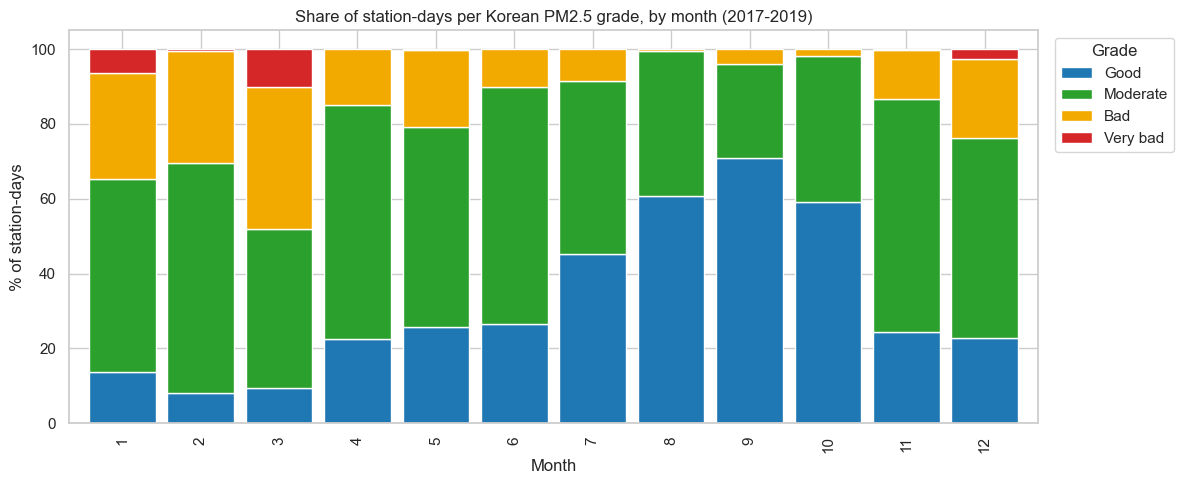

pm25_grade,Good,Moderate,Bad,Very bad
month,,,,
1,13.7,51.5,28.4,6.3
2,8.1,61.6,29.9,0.4
3,9.5,42.4,38.1,10.0
4,22.5,62.7,14.8,0.0
5,25.8,53.3,20.7,0.2
6,26.5,63.5,10.0,0.0
7,45.2,46.3,8.5,0.0
8,60.7,38.8,0.4,0.0
9,70.9,25.2,3.9,0.0


In [6]:
share = (d.dropna(subset=["pm25"])
           .groupby("month")["pm25_grade"].value_counts(normalize=True)
           .mul(100).unstack()[GRADE_LABELS])
ax = share.plot(kind="bar", stacked=True, figsize=(12, 5), color=[GRADE_COLORS[g] for g in GRADE_LABELS], width=0.85)
ax.set_title("Share of station-days per Korean PM2.5 grade, by month (2017-2019)")
ax.set_ylabel("% of station-days")
ax.set_xlabel("Month")
ax.legend(title="Grade", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(config.FIGURES / "02_grade_share_by_month.png", dpi=120)
plt.show()
share.round(1)

**Interpretation.** Seasonality is the dominant pattern. The median station-day PM2.5 peaks in March (34.4 ug/m3) and is lowest in September (10.7 ug/m3). In March 48.1% of station-days are Bad or Very bad (38.1% + 10.0%), against 0.4% in August. Winter and early spring (December to March) concentrate the Very bad days; summer and early autumn are mostly Good or Moderate.

## 4. Weekday and hour of day

In [7]:
weekday = city.groupby(city.index.weekday)[["pm25", "pm10", "no2"]].median()
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday.round(3)

,pm25,pm10,no2
Mon,21.249,38.011,0.027
Tue,20.504,36.847,0.028
Wed,20.184,37.509,0.026
Thu,20.397,37.965,0.027
Fri,21.063,38.084,0.028
Sat,21.463,39.005,0.026
Sun,21.347,36.218,0.022


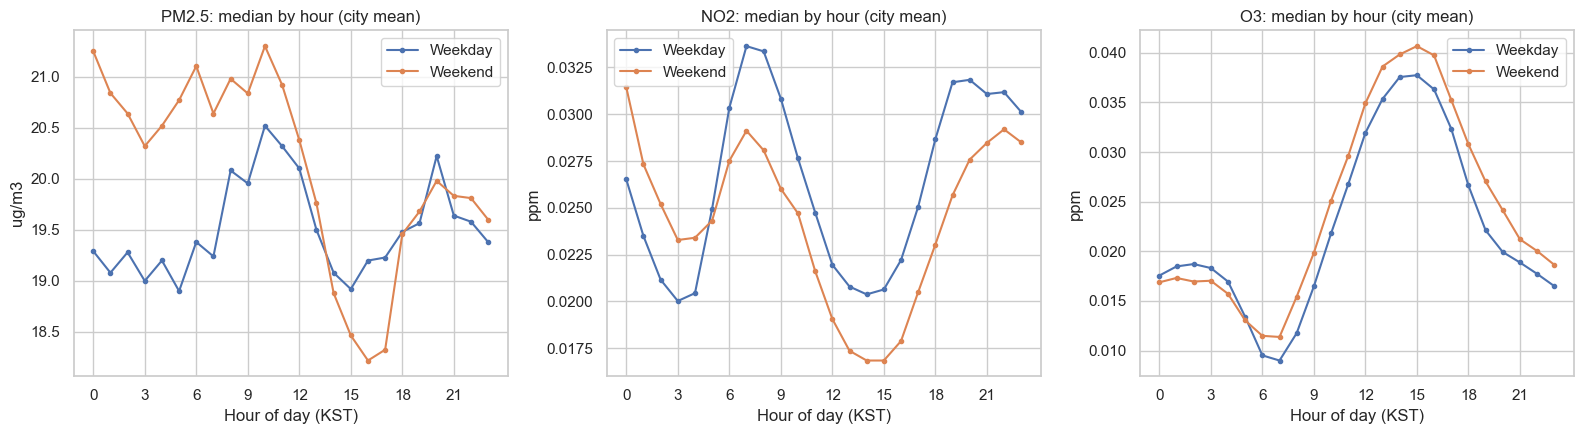

pm25: weekday peak at 10h (20.520), minimum at 5h (18.900)
no2: weekday peak at 7h (0.034), minimum at 3h (0.020)
o3: weekday peak at 15h (0.038), minimum at 7h (0.009)


In [8]:
h = hourly.groupby("datetime")[["pm25", "no2", "o3"]].mean()
h["hour"] = h.index.hour
h["day_type"] = np.where(h.index.weekday >= 5, "Weekend", "Weekday")
profile = h.groupby(["day_type", "hour"])[["pm25", "no2", "o3"]].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, unit in zip(axes, ["pm25", "no2", "o3"], ["ug/m3", "ppm", "ppm"]):
    for day_type, grp in profile[col].groupby(level=0):
        ax.plot(grp.index.get_level_values(1), grp.values, marker="o", ms=3, label=day_type)
    ax.set_title(f"{col.upper().replace('PM25', 'PM2.5')}: median by hour (city mean)")
    ax.set_xlabel("Hour of day (KST)")
    ax.set_ylabel(unit)
    ax.set_xticks(range(0, 24, 3))
    ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "02_hourly_profile.png", dpi=120)
plt.show()
for col in ["pm25", "no2", "o3"]:
    wk = profile.loc["Weekday", col]
    print(f"{col}: weekday peak at {wk.idxmax()}h ({wk.max():.3f}), minimum at {wk.idxmin()}h ({wk.min():.3f})")

**Interpretation.** The weekday and weekend medians of PM2.5 are close (20.2 to 21.5 ug/m3 by weekday), so PM2.5 is not driven mainly by the local weekly traffic cycle. NO2, a traffic marker, does show it: its median falls to 0.022 ppm on Sundays against 0.026-0.028 ppm on other days, and on weekdays it peaks at 7h, the morning rush hour. O3 behaves in the opposite way: it is formed by sunlight, so it peaks at 15h and is lowest at 7h, when fresh NO emissions consume it. On weekdays the hourly PM2.5 cycle is flat (median between 18.9 and 20.5 ug/m3 across hours).